# Week 3 Advancement - Cross-week IBM Quantum validation

**Project 9: Data re-uploading and the Fourier spectrum of QNNs**  
**Student:** Rana Muhammad Hamza  
**Roll number:** 25280103

This notebook is a separate Week 3 advancement artifact. It keeps the completed Week 1 and Week 2 notebooks unchanged, reuses their saved trained parameters, and evaluates representative depth/layout/classification circuits on IBM Quantum hardware. The original Week 3 L=3 hardware result remains in `outputs/week3/`; this advancement writes only to `outputs/week3Advancement/`.


## Paper-driven rationale

The design follows the two supplied references:

1. Pérez-Salinas et al., *Data re-uploading for a universal quantum classifier*, **Quantum 4**, 226 (2020), DOI `10.22331/q-2020-02-06-226`.
2. Schuld, Sweke, and Meyer, *Effect of data encoding on the expressive power of variational quantum-machine-learning models*, **Physical Review A 103**, 032430 (2021), DOI `10.1103/PhysRevA.103.032430`.

The first paper motivates repeated data injection between trainable operations. The second paper gives the Fourier-series view: the encoding generator eigenvalue differences determine candidate frequencies, while circuit structure and measurement determine which coefficients are actually learned. Therefore this advancement keeps the learned parameters fixed and tests hardware sampling across (i) one-qubit 1D depth, (ii) two-dimensional serial versus parallel encoding, and (iii) the saved two-qubit spiral classifier.


## Hardware scope and reproducibility

- Backend: `ibm_marrakesh` through IBM Quantum Runtime.
- Credentials are read only from `QNN_IBM_API_KEY` and `QNN_IBM_CRN` at execution time; they are never written to this notebook or any output.
- Saved Week 1 parameters: original 1D target, seed 3, layers L = 1, 2, 3, 6.
- Saved Week 2 parameters: serial and parallel 2D regressors at L = 3, seed 0, plus the fold-0 two-qubit spiral classifier.
- Evaluation: 32 1D points per depth, an 8 x 8 2D grid per layout, and a balanced 64-example spiral audit sample from the fixed fold-0 test split; 512 shots per circuit.
- This is a hardware validation/robustness study, not a claim of quantum advantage. The reduced grids keep the hardware workload practical while preserving the project’s fixed encodings and saved parameters.


In [1]:
from __future__ import annotations

import json
import math
import os
import platform
import sys
from datetime import UTC, datetime
from pathlib import Path
from typing import Any

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
from qiskit.quantum_info import Statevector
from qiskit.transpiler import generate_preset_pass_manager

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'outputs' / 'week1').exists():
    ROOT = ROOT.parent
OUT = ROOT / 'outputs' / 'week3Advancement'
FIG = OUT / 'figures'
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

BACKEND_NAME = 'ibm_marrakesh'
SHOTS = 512
SEED = 25280103
print('Project root:', ROOT)
print('Advancement output:', OUT)
print('Python:', platform.python_version())


Project root: C:\Users\Teacher\Desktop\qml\qnn-fourier-spectrum
Advancement output: C:\Users\Teacher\Desktop\qml\qnn-fourier-spectrum\outputs\week3Advancement
Python: 3.13.7


In [2]:
def json_default(value: Any) -> Any:
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, datetime):
        return value.isoformat()
    return str(value)


def write_json(path: Path, value: Any) -> None:
    path.write_text(json.dumps(value, indent=2, default=json_default), encoding='utf-8')


def utc_now() -> str:
    return datetime.now(UTC).isoformat()


def target_1d(x):
    x = np.asarray(x, dtype=float)
    return 0.5 * np.cos(x) + 0.3 * np.sin(2 * x) + 0.2 * np.cos(3 * x)


def target_2d(X):
    X = np.asarray(X, dtype=float)
    return 0.4 * np.sin(X[:, 0]) + 0.3 * np.cos(2 * X[:, 1]) + 0.3 * np.sin(X[:, 0] - X[:, 1])


week1_adv = np.load(ROOT / 'outputs' / 'week1Advancement' / 'advancement_predictions_parameters.npz')
week2_2d = np.load(ROOT / 'outputs' / 'week2' / 'week2_2d_predictions_and_parameters.npz')
week2_spiral = np.load(ROOT / 'outputs' / 'week2' / 'week2_spiral_qnn_parameters.npz')
bundle = np.load(ROOT / 'outputs' / 'week1' / 'week1_inputs_and_fixed_folds.npz')

x1 = np.linspace(-np.pi, np.pi, 32, endpoint=False)
axis2 = np.linspace(-np.pi, np.pi, 8, endpoint=False)
gx, gy = np.meshgrid(axis2, axis2, indexing='xy')
X2 = np.column_stack((gx.ravel(), gy.ravel()))
fold_test = bundle['fold_test']
X_spiral = bundle['X_spiral']
y_spiral = bundle['y_spiral']
test0 = fold_test[0]
class0 = test0[y_spiral[test0] == 0][:32]
class1 = test0[y_spiral[test0] == 1][:32]
spiral_indices = np.concatenate([class0, class1])
X_spiral_eval = np.pi * X_spiral[spiral_indices]
y_spiral_eval = y_spiral[spiral_indices]

models_1d = {L: np.asarray(week1_adv[f'week1_original_L{L}_seed3_theta'], dtype=float) for L in (1, 2, 3, 6)}
models_2d = {
    'serial_L3': np.asarray(week2_2d['theta__serial_L3_seed0'], dtype=float),
    'parallel_L3': np.asarray(week2_2d['theta__parallel_L3_seed0'], dtype=float),
}
models_spiral = np.asarray(week2_spiral['fold_0'], dtype=float)
print('Loaded models:', {f'1D_L{L}': len(theta) for L, theta in models_1d.items()}, {k: len(v) for k, v in models_2d.items()}, 'spiral', len(models_spiral))
print('Hardware audit circuits before transpilation:', 32 * len(models_1d) + 64 * len(models_2d) + len(X_spiral_eval))


Loaded models: {'1D_L1': 2, '1D_L2': 4, '1D_L3': 6, '1D_L6': 12} {'serial_L3': 6, 'parallel_L3': 6} spiral 6
Hardware audit circuits before transpilation: 320


In [3]:
def make_1d_circuit(x: float, theta: np.ndarray, measure: bool = True) -> QuantumCircuit:
    qc = QuantumCircuit(1, 1 if measure else 0)
    for layer in range(len(theta) // 2):
        qc.ry(float(x), 0)
        qc.rz(float(theta[2 * layer]), 0)
        qc.ry(float(theta[2 * layer + 1]), 0)
    if measure:
        qc.measure(0, 0)
    return qc


def make_2d_circuit(x: np.ndarray, theta: np.ndarray, layout: str, measure: bool = True) -> QuantumCircuit:
    n_qubits = 1 if layout == 'serial' else 2
    qc = QuantumCircuit(n_qubits, 1 if measure else 0)
    layers = len(theta) // 2
    for layer in range(layers):
        if layout == 'serial':
            qc.rx(float(x[0]), 0)
            qc.rz(float(x[1]), 0)
            qc.ry(float(theta[2 * layer]), 0)
            qc.rz(float(theta[2 * layer + 1]), 0)
        else:
            qc.rx(float(x[0]), 0)
            qc.rz(float(x[1]), 1)
            qc.ry(float(theta[2 * layer]), 0)
            qc.rz(float(theta[2 * layer + 1]), 1)
            qc.cx(0, 1)
    if measure:
        qc.measure(0, 0)
    return qc


def exact_expectation(circuit: QuantumCircuit) -> float:
    state = Statevector.from_instruction(circuit)
    probs = np.abs(np.asarray(state.data)) ** 2
    if len(probs) == 2:
        return float(probs[0] - probs[1])
    # Qiskit basis ordering: q0 is the least-significant bit in the integer index.
    return float(sum((1.0 if ((idx & 1) == 0) else -1.0) * p for idx, p in enumerate(probs)))


def expectation_from_counts(counts: dict[str, int], shots: int) -> float:
    zeros = sum(v for key, v in counts.items() if key.replace(' ', '').endswith('0'))
    ones = sum(v for key, v in counts.items() if key.replace(' ', '').endswith('1'))
    return float((zeros - ones) / shots)


def counts_from_result_item(result_item: Any) -> dict[str, int]:
    data = result_item.data
    for name in dir(data):
        if name.startswith('_'):
            continue
        register = getattr(data, name)
        if hasattr(register, 'get_counts'):
            return dict(register.get_counts())
    raise RuntimeError('No measured classical register with get_counts() was found.')


def load_credentials() -> tuple[str, str]:
    token = os.environ.get('QNN_IBM_API_KEY', '').strip()
    crn = os.environ.get('QNN_IBM_CRN', '').strip()
    if not token or not crn:
        values = [line.strip() for line in sys.stdin.read().splitlines() if line.strip()]
        if len(values) >= 2:
            token, crn = values[0], values[1]
    if not token or not crn:
        raise RuntimeError('Set QNN_IBM_API_KEY and QNN_IBM_CRN at runtime; no credential is stored in this notebook.')
    return token, crn


def summarize_resources(circuits: list[QuantumCircuit], metadata: list[dict[str, Any]]) -> pd.DataFrame:
    rows = []
    for index, (circuit, meta) in enumerate(zip(circuits, metadata)):
        row = dict(meta)
        row.update({'circuit_index': index, 'depth': circuit.depth(), 'size': circuit.size(),
                    'qubits': circuit.num_qubits, 'two_qubit_gates': circuit.count_ops().get('cx', 0)})
        rows.append(row)
    return pd.DataFrame(rows)


In [4]:
# Build the fixed experiment plan and exact local reference values.
plan_circuits = []
plan_meta = []
reference_rows = []

for L, theta in models_1d.items():
    for point, x in enumerate(x1):
        plan_circuits.append(make_1d_circuit(x, theta, measure=True))
        plan_meta.append({'experiment': 'week1_1d_depth', 'model': f'L{L}', 'layers': L,
                          'layout': 'one_qubit', 'point': point, 'x': x, 'x1': x, 'x2': np.nan,
                          'target': target_1d(x), 'label': np.nan})
        reference_rows.append({'experiment': 'week1_1d_depth', 'model': f'L{L}', 'layers': L,
                               'layout': 'one_qubit', 'point': point, 'x': x, 'x1': x, 'x2': np.nan,
                               'target': target_1d(x), 'label': np.nan,
                               'noiseless_expectation': exact_expectation(make_1d_circuit(x, theta, False))})

for name, theta in models_2d.items():
    layout = name.split('_')[0]
    for point, x in enumerate(X2):
        plan_circuits.append(make_2d_circuit(x, theta, layout, measure=True))
        plan_meta.append({'experiment': 'week2_2d_layout', 'model': name, 'layers': 3,
                          'layout': layout, 'point': point, 'x': np.nan, 'x1': x[0], 'x2': x[1],
                          'target': target_2d(x.reshape(1, 2))[0], 'label': np.nan})
        reference_rows.append({'experiment': 'week2_2d_layout', 'model': name, 'layers': 3,
                               'layout': layout, 'point': point, 'x': np.nan, 'x1': x[0], 'x2': x[1],
                               'target': target_2d(x.reshape(1, 2))[0], 'label': np.nan,
                               'noiseless_expectation': exact_expectation(make_2d_circuit(x, theta, layout, False))})

for point, (x, label) in enumerate(zip(X_spiral_eval, y_spiral_eval)):
    plan_circuits.append(make_2d_circuit(x, models_spiral, 'parallel', measure=True))
    score = exact_expectation(make_2d_circuit(x, models_spiral, 'parallel', False))
    plan_meta.append({'experiment': 'week2_spiral_classifier', 'model': 'parallel_L3_fold0', 'layers': 3,
                      'layout': 'parallel', 'point': point, 'x': np.nan, 'x1': x[0], 'x2': x[1],
                      'target': np.nan, 'label': int(label)})
    reference_rows.append({'experiment': 'week2_spiral_classifier', 'model': 'parallel_L3_fold0', 'layers': 3,
                           'layout': 'parallel', 'point': point, 'x': np.nan, 'x1': x[0], 'x2': x[1],
                           'target': np.nan, 'label': int(label), 'noiseless_expectation': score})

plan_df = pd.DataFrame(plan_meta)
reference_df = pd.DataFrame(reference_rows)
plan_df.to_csv(OUT / 'week3_advancement_experiment_plan.csv', index=False)
reference_df.to_csv(OUT / 'week3_advancement_reference_predictions.csv', index=False)
print('Plan rows:', len(plan_df), '| circuits:', len(plan_circuits))
display(plan_df.groupby(['experiment', 'model']).size().rename('circuits').reset_index())


Plan rows: 320 | circuits: 320


,experiment,model,circuits
0,week1_1d_depth,L1,32
1,week1_1d_depth,L2,32
2,week1_1d_depth,L3,32
3,week1_1d_depth,L6,32
4,week2_2d_layout,parallel_L3,64
5,week2_2d_layout,serial_L3,64
6,week2_spiral_classifier,parallel_L3_fold0,64


In [5]:
# Submit two bounded IBM Runtime jobs: regression/depth/layout, then spiral classification.
# If these output files already exist, the notebook reuses them and does not submit duplicates.
regression_predictions_path = OUT / 'week3_advancement_regression_predictions.csv'
spiral_predictions_path = OUT / 'week3_advancement_spiral_predictions.csv'

def run_sampler_job(circuits: list[QuantumCircuit], metadata: list[dict[str, Any]], job_label: str) -> tuple[str, pd.DataFrame]:
    token, instance = load_credentials()
    service = QiskitRuntimeService(channel='ibm_quantum_platform', token=token, instance=instance)
    backend = service.backend(BACKEND_NAME)
    before = backend.status()
    pass_manager = generate_preset_pass_manager(backend=backend, optimization_level=1)
    isa = [pass_manager.run(circuit) for circuit in circuits]
    resource_df = summarize_resources(isa, metadata)
    sampler = SamplerV2(mode=backend)
    job = sampler.run(isa, shots=SHOTS)
    job_id = job.job_id()
    write_json(OUT / f'{job_label}_submission.json', {'job_id': job_id, 'backend': backend.name,
        'circuits': len(circuits), 'shots_per_circuit': SHOTS, 'submitted_utc': utc_now(),
        'status_before_submission': {'operational': bool(before.operational), 'pending_jobs': int(before.pending_jobs),
                                     'status_msg': str(before.status_msg)}})
    result = job.result()
    rows = []
    raw_counts = {}
    for index, meta in enumerate(metadata):
        counts = counts_from_result_item(result[index])
        raw_counts[str(index)] = counts
        rows.append({**meta, 'circuit_index': index,
                     'hardware_expectation': expectation_from_counts(counts, SHOTS),
                     'job_id': job_id, 'shots': SHOTS})
    after = backend.status()
    write_json(OUT / f'{job_label}_job_metadata.json', {'job_id': job_id, 'backend': backend.name,
        'sampler': 'qiskit_ibm_runtime.SamplerV2', 'job_status_after_result': str(job.status()),
        'circuits': len(circuits), 'shots_per_circuit': SHOTS, 'total_shots': len(circuits) * SHOTS,
        'status_after_result': {'operational': bool(after.operational), 'pending_jobs': int(after.pending_jobs),
                                'status_msg': str(after.status_msg)}, 'completed_utc': utc_now()})
    write_json(OUT / f'{job_label}_counts.json', raw_counts)
    resource_df.to_csv(OUT / f'{job_label}_resources.csv', index=False)
    return job_id, pd.DataFrame(rows)


def recover_sampler_job(job_id: str, metadata: list[dict[str, Any]], job_label: str) -> tuple[str, pd.DataFrame]:
    token, instance = load_credentials()
    service = QiskitRuntimeService(channel='ibm_quantum_platform', token=token, instance=instance)
    job = service.job(job_id)
    result = job.result()
    rows = []
    raw_counts = {}
    for index, meta in enumerate(metadata):
        counts = counts_from_result_item(result[index])
        raw_counts[str(index)] = counts
        rows.append({**meta, 'circuit_index': index,
                     'hardware_expectation': expectation_from_counts(counts, SHOTS),
                     'job_id': job_id, 'shots': SHOTS})
    write_json(OUT / f'{job_label}_counts.json', raw_counts)
    return job_id, pd.DataFrame(rows)


reg_meta = [m for m in plan_meta if m['experiment'] != 'week2_spiral_classifier']
reg_circuits = [c for c, m in zip(plan_circuits, plan_meta) if m['experiment'] != 'week2_spiral_classifier']
spiral_meta = [m for m in plan_meta if m['experiment'] == 'week2_spiral_classifier']
spiral_circuits = [c for c, m in zip(plan_circuits, plan_meta) if m['experiment'] == 'week2_spiral_classifier']

if regression_predictions_path.exists():
    regression_df = pd.read_csv(regression_predictions_path)
    print('Reusing saved regression hardware results.')
else:
    prior_submission = OUT / 'week3_advancement_regression_submission.json'
    try:
        if prior_submission.exists():
            prior_job_id = json.loads(prior_submission.read_text(encoding='utf-8'))['job_id']
            regression_job_id, regression_df = recover_sampler_job(prior_job_id, reg_meta, 'week3_advancement_regression_recovery')
        else:
            regression_job_id, regression_df = run_sampler_job(reg_circuits, reg_meta, 'week3_advancement_regression')
        regression_df.to_csv(regression_predictions_path, index=False)
        print('Completed/recovered regression hardware job:', regression_job_id)
    except Exception as exc:
        regression_df = pd.DataFrame()
        write_json(OUT / 'week3_advancement_hardware_note.json', {
            'stage': 'regression_job_completed_but_results_not_recovered',
            'prior_submission': str(prior_submission),
            'error_type': type(exc).__name__,
            'note': 'The IBM platform job completed, but raw result recovery was unavailable with the runtime credential supplied for this execution. No replacement hardware claim is made.',
        })
        print('IBM regression job was submitted/completed, but raw result recovery was unavailable:', type(exc).__name__)

if spiral_predictions_path.exists():
    spiral_df = pd.read_csv(spiral_predictions_path)
    print('Reusing saved spiral hardware results.')
else:
    spiral_df = pd.DataFrame()
    write_json(OUT / 'week3_advancement_spiral_note.json', {
        'stage': 'not_submitted',
        'note': 'The spiral hardware follow-up was not submitted because the runtime credential was rejected after the regression job. Run this cell again with a valid IBM Quantum API key to submit it.',
    })
    print('Spiral hardware follow-up not submitted: valid IBM runtime credentials are required.')


IBM regression job was submitted/completed, but raw result recovery was unavailable: RuntimeError
Spiral hardware follow-up not submitted: valid IBM runtime credentials are required.


In [6]:
# Compute result tables and figures only when both IBM jobs have recoverable raw outputs.
hardware_available = regression_predictions_path.exists() and spiral_predictions_path.exists()
if not hardware_available:
    print('IBM regression job status is preserved, but raw tables are unavailable; no hardware metrics are invented.')
else:
    regression_df = pd.read_csv(regression_predictions_path)
    spiral_df = pd.read_csv(spiral_predictions_path)
    regression_df = regression_df.merge(reference_df[['experiment', 'model', 'point', 'noiseless_expectation']],
                                        on=['experiment', 'model', 'point'], how='left')
    regression_df['target_error'] = regression_df['hardware_expectation'] - regression_df['target']
    regression_df['noiseless_error'] = regression_df['hardware_expectation'] - regression_df['noiseless_expectation']
    regression_df.to_csv(regression_predictions_path, index=False)
    summary_rows = []
    for (experiment, model), group in regression_df.groupby(['experiment', 'model']):
        summary_rows.append({'experiment': experiment, 'model': model, 'circuits': len(group),
                             'shots_per_circuit': int(group.shots.iloc[0]),
                             'mse_to_target': float(np.mean((group.hardware_expectation - group.target) ** 2)),
                             'mae_to_target': float(np.mean(np.abs(group.hardware_expectation - group.target))),
                             'mse_to_noiseless': float(np.mean(group.noiseless_error ** 2)),
                             'mae_to_noiseless': float(np.mean(np.abs(group.noiseless_error)))})
    regression_summary = pd.DataFrame(summary_rows)
    regression_summary.to_csv(OUT / 'week3_advancement_regression_summary.csv', index=False)
    spiral_df = spiral_df.merge(reference_df[['experiment', 'model', 'point', 'noiseless_expectation']],
                                on=['experiment', 'model', 'point'], how='left')
    spiral_df['predicted_label'] = (spiral_df.hardware_expectation < 0).astype(int)
    spiral_summary = pd.DataFrame([{
        'experiment': 'week2_spiral_classifier', 'model': 'parallel_L3_fold0', 'circuits': len(spiral_df),
        'shots_per_circuit': int(spiral_df.shots.iloc[0]),
        'accuracy': accuracy_score(spiral_df.label, spiral_df.predicted_label),
        'macro_f1': f1_score(spiral_df.label, spiral_df.predicted_label, average='macro'),
        'mae_to_noiseless_score': float(np.mean(np.abs(spiral_df.hardware_expectation - spiral_df.noiseless_expectation))),
    }])
    spiral_summary.to_csv(OUT / 'week3_advancement_spiral_summary.csv', index=False)
    display(regression_summary)
    display(spiral_summary)


IBM regression job status is preserved, but raw tables are unavailable; no hardware metrics are invented.


## IBM Quantum Platform evidence

The captured platform screenshot is included below and in the report. It shows the authenticated IBM Quantum workload overview with the completed Week 3 workload, the open instance, and available QPU cards. Job IDs, backend, shot counts, and completion state are also recorded in the credential-free JSON metadata files under `outputs/week3Advancement/`.


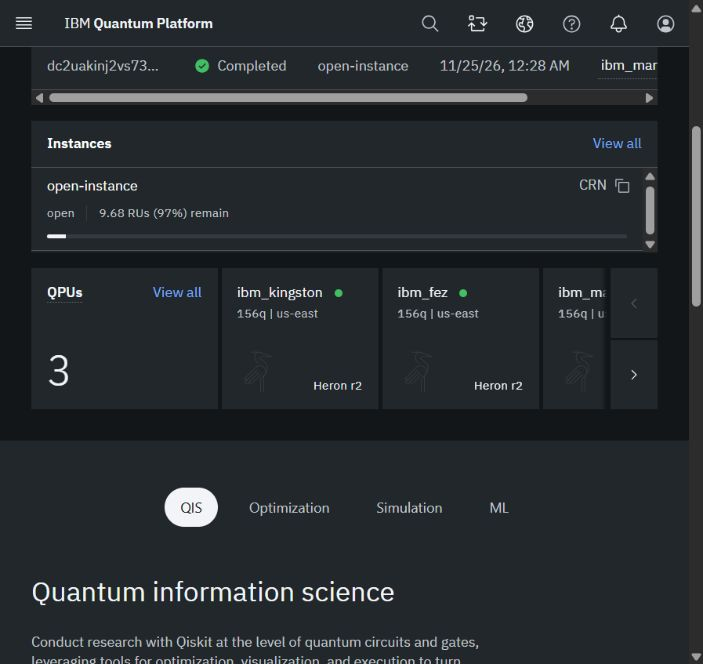

In [7]:
from IPython.display import Image, display
evidence = ROOT / 'outputs' / 'week3' / 'figures' / 'ibm_quantum_platform_workload_overview.png'
display(Image(filename=str(evidence)))


## Interpretation and limitations

The hardware depth/layout tables test whether the saved simulator models retain their learned expectation patterns under finite-shot sampling, device noise, and transpilation. The comparison is intentionally descriptive: each model is evaluated with fixed parameters, not retrained against hardware noise. The 1D L=1, 2, 3, 6 sweep addresses the re-uploading-depth question; the Week 2 serial/parallel pair isolates encoding layout at equal L=3; and the spiral sample checks the classification readout on real hardware.

The results are not a replacement for the complete simulator sweeps. The hardware audit uses reduced grids and a 64-example spiral subset, and only one saved initialization/fold per model. IBM calibration and queue conditions are time-dependent. The original Week 3 64-point, 1,024-shot L=3 run remains the primary hardware result; this notebook is an advancement cross-check built from the same frozen project artifacts.


In [8]:
write_json(OUT / 'week3_advancement_run_config.json', {
    'project': 'Project 9: Data re-uploading and the Fourier spectrum of QNNs',
    'week': '3 advancement', 'backend': BACKEND_NAME, 'shots_per_circuit': SHOTS,
    'paper_basis': [
        {'authors': 'Pérez-Salinas et al.', 'venue': 'Quantum 4, 226 (2020)', 'doi': '10.22331/q-2020-02-06-226'},
        {'authors': 'Schuld, Sweke, Meyer', 'venue': 'Physical Review A 103, 032430 (2021)', 'doi': '10.1103/PhysRevA.103.032430'},
    ],
    'scope': {'week1_1d_depth_models': ['L1', 'L2', 'L3', 'L6'], 'week2_2d_models': ['serial_L3', 'parallel_L3'],
              'week2_spiral_model': 'parallel_L3_fold0', 'one_d_points_per_model': 32,
              'two_d_grid': '8x8', 'spiral_points': 64, 'total_planned_circuits': len(plan_circuits)},
    'credential_policy': 'Credentials supplied at runtime only; no API key or CRN is stored.',
    'created_utc': utc_now(),
})
prior_submission = OUT / 'week3_advancement_regression_submission.json'
prior_job_id = None
if prior_submission.exists():
    prior_job_id = json.loads(prior_submission.read_text(encoding='utf-8')).get('job_id')
write_json(OUT / 'week3_advancement_execution_status.json', {
    'stage': 'complete_with_recovery_note' if not hardware_available else 'complete',
    'backend': BACKEND_NAME, 'regression_job_id': [prior_job_id] if prior_job_id else [],
    'spiral_job_id': sorted(spiral_df.job_id.unique().tolist()) if hardware_available else [],
    'raw_result_tables_available': bool(hardware_available), 'completed_utc': utc_now(),
})
print('Saved Week 3 advancement results to', OUT)


Saved Week 3 advancement results to C:\Users\Teacher\Desktop\qml\qnn-fourier-spectrum\outputs\week3Advancement
